In [1]:
# 打开文件选择窗口
from google.colab import files

# 上传你刚才拍摄的两张照片
letter_uploads = files.upload()

# 显示上传成功的文件名
print("上传完成，文件如下：")

for filename in letter_uploads:
    print(filename)


Saving 微信图片_20261019234533_160_2.jpg to 微信图片_20261019234533_160_2.jpg
Saving 微信图片_20261019234534_161_2.jpg to 微信图片_20261019234534_161_2.jpg
上传完成，文件如下：
微信图片_20261019234533_160_2.jpg
微信图片_20261019234534_161_2.jpg


照片1：微信图片_20261019234533_160_2.jpg
高度：3024像素，宽度：4032像素
照片2：微信图片_20261019234534_161_2.jpg
高度：3024像素，宽度：4032像素


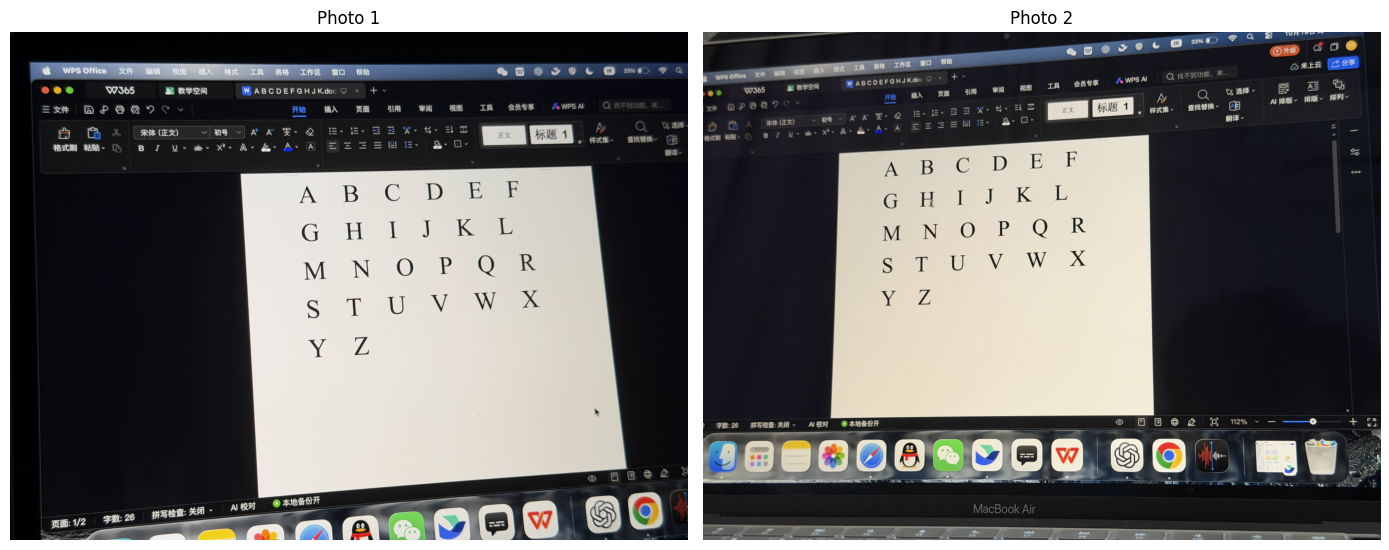

In [2]:
# 准备读取和显示图片的工具
import io
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

# 保存文件名和读取后的图片
letter_names = list(letter_uploads.keys())
letter_images = []

# 逐张读取照片
for name in letter_names:
    photo = Image.open(io.BytesIO(letter_uploads[name]))

    # 按手机记录的方向摆正照片
    photo = ImageOps.exif_transpose(photo)

    # 转成统一的彩色格式
    photo = np.array(photo.convert("RGB"))
    letter_images.append(photo)

# 并排显示两张照片
plt.figure(figsize=(14, 7))

for i, photo in enumerate(letter_images):
    plt.subplot(1, len(letter_images), i + 1)
    plt.imshow(photo)
    plt.title(f"Photo {i + 1}")
    plt.axis("off")

    print(f"照片{i + 1}：{letter_names[i]}")
    print(f"高度：{photo.shape[0]}像素，宽度：{photo.shape[1]}像素")

plt.tight_layout()
plt.show()

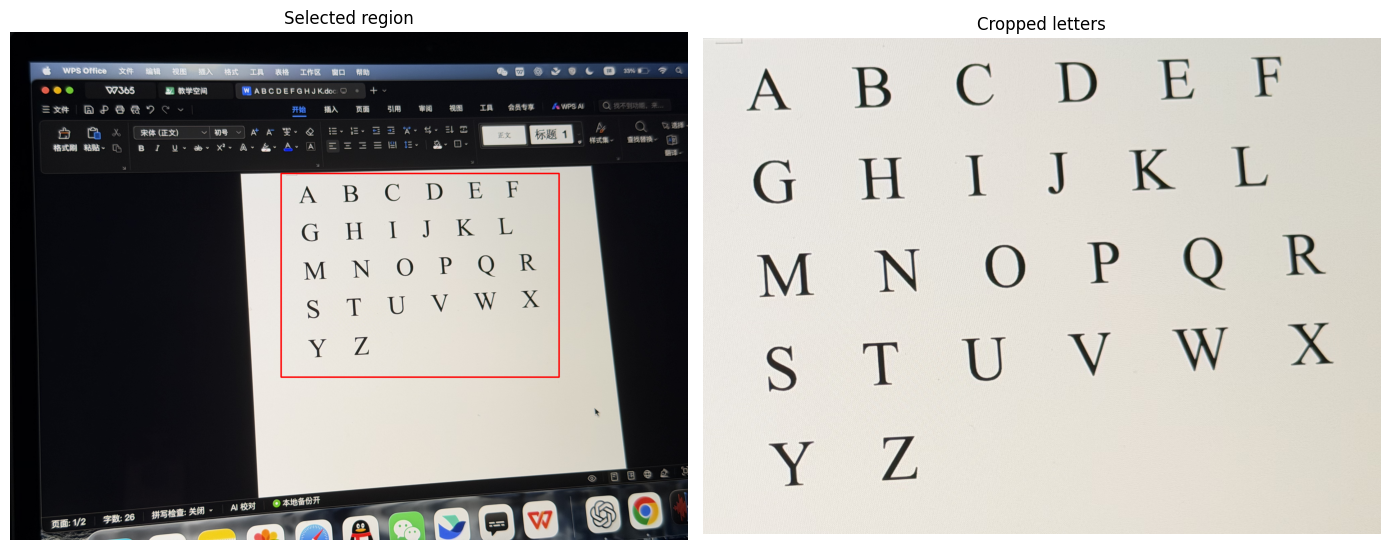

裁剪完成！
裁剪后尺寸（高度，宽度）： (1210, 1653)


In [4]:
# 选择第一张照片
# Python从0开始编号，所以[0]表示第一张
selected_photo = letter_images[0].copy()

# 获取照片的高度和宽度
height, width = selected_photo.shape[:2]

# 设置裁剪区域：左边、右边、上边、下边
left = int(width * 0.40)
right = int(width * 0.81)
top = int(height * 0.28)
bottom = int(height * 0.68)

# 裁出字母区域，保存为letter_roi
letter_roi = selected_photo[top:bottom, left:right].copy()

# 在原图副本上画红框，显示裁剪位置
preview = selected_photo.copy()
cv2.rectangle(
    preview,
    (left, top),
    (right, bottom),
    (255, 0, 0),
    8
)

# 左边显示裁剪位置，右边显示裁剪结果
plt.figure(figsize=(14, 7))

plt.subplot(1, 2, 1)
plt.imshow(preview)
plt.title("Selected region")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(letter_roi)
plt.title("Cropped letters")
plt.axis("off")

plt.tight_layout()
plt.show()

print("裁剪完成！")
print("裁剪后尺寸（高度，宽度）：", letter_roi.shape[:2])

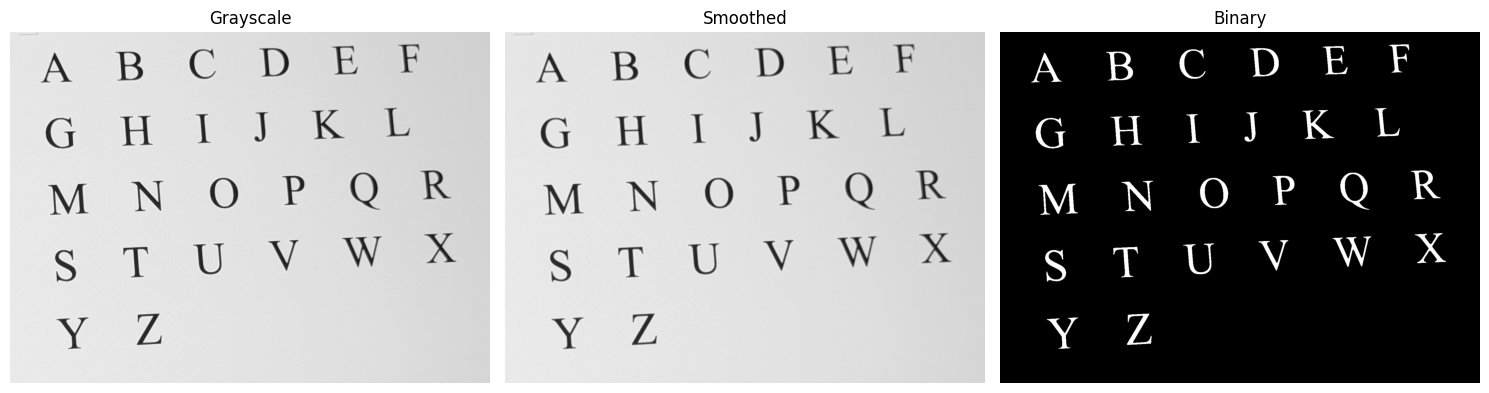

二值化完成！
自动选择的阈值： 145.0
二值图中的像素值： [  0 255]


In [5]:
# 第一步：彩色图转成灰度图
# 前面用PIL读取的是RGB格式，因此这里使用COLOR_RGB2GRAY
letter_gray = cv2.cvtColor(letter_roi, cv2.COLOR_RGB2GRAY)

# 第二步：轻微平滑，减轻细小噪声
letter_blurred = cv2.GaussianBlur(letter_gray, (5, 5), 0)

# 第三步：用Otsu方法自动选择阈值
# 反转颜色，让字母为白色、背景为黑色
threshold_value, letter_binary = cv2.threshold(
    letter_blurred,
    0,
    255,
    cv2.THRESH_BINARY_INV | cv2.THRESH_OTSU
)

# 显示三个处理阶段
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(letter_gray, cmap="gray", vmin=0, vmax=255)
plt.title("Grayscale")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(letter_blurred, cmap="gray", vmin=0, vmax=255)
plt.title("Smoothed")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(letter_binary, cmap="gray", vmin=0, vmax=255)
plt.title("Binary")
plt.axis("off")

plt.tight_layout()
plt.show()

print("二值化完成！")
print("自动选择的阈值：", threshold_value)
print("二值图中的像素值：", np.unique(letter_binary))

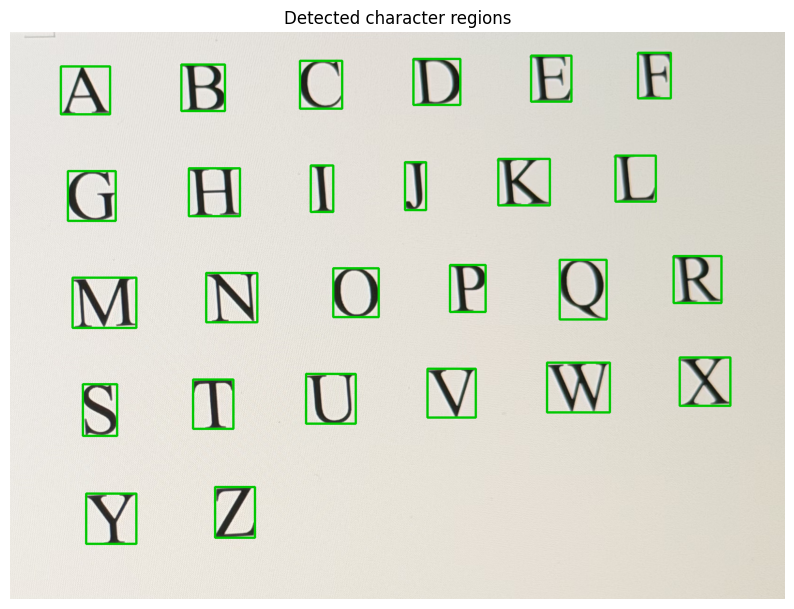

检测到的候选字母数量： 26


In [6]:
# 寻找白色区域的外轮廓
# 只取外轮廓，避免把O、B等字母内部的孔洞重复计算
contours, _ = cv2.findContours(
    letter_binary.copy(),
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

# 保存每个候选字母的位置
letter_boxes = []

# 获取二值图的高度和宽度
roi_height, roi_width = letter_binary.shape

for contour in contours:
    # 得到包围这个区域的矩形
    x, y, w, h = cv2.boundingRect(contour)
    area = cv2.contourArea(contour)

    # 根据尺寸过滤小噪点和异常大区域
    if (
        h >= roi_height * 0.04
        and h <= roi_height * 0.25
        and w >= 3
        and area >= roi_height * roi_width * 0.00005
    ):
        letter_boxes.append((x, y, w, h))

# 在彩色图副本上画出绿色方框
boxed_letters = letter_roi.copy()

for x, y, w, h in letter_boxes:
    cv2.rectangle(
        boxed_letters,
        (x, y),
        (x + w, y + h),
        (0, 200, 0),
        3
    )

plt.figure(figsize=(10, 8))
plt.imshow(boxed_letters)
plt.title("Detected character regions")
plt.axis("off")
plt.show()

print("检测到的候选字母数量：", len(letter_boxes))

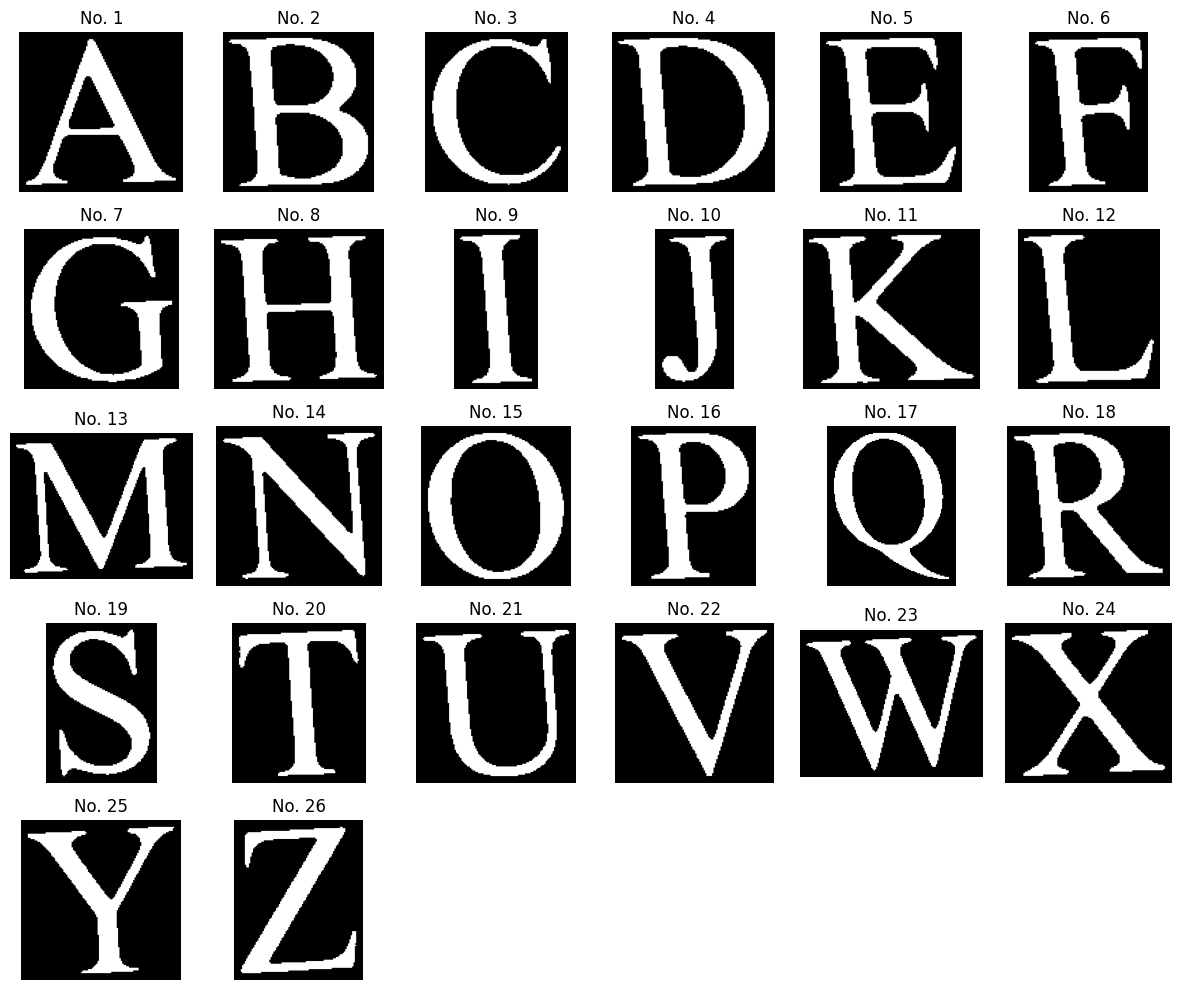

检测到的行数： 5
每行的字母数量： [6, 6, 6, 6, 2]
单独裁出的字母总数： 26


In [7]:
# 根据字母高度，设置判断“是否属于同一行”的距离
row_tolerance = np.median([box[3] for box in letter_boxes]) * 0.65

# 先按方框中心的上下位置排列
boxes_by_height = sorted(
    letter_boxes,
    key=lambda box: box[1] + box[3] / 2
)

# 把位置接近的字母归为同一行
letter_rows = []

for box in boxes_by_height:
    center_y = box[1] + box[3] / 2

    if (
        not letter_rows
        or center_y - np.mean([
            b[1] + b[3] / 2 for b in letter_rows[-1]
        ]) > row_tolerance
    ):
        letter_rows.append([])

    letter_rows[-1].append(box)

# 每一行再按从左到右排列
ordered_letter_boxes = []

for row in letter_rows:
    row.sort(key=lambda box: box[0])
    ordered_letter_boxes.extend(row)

# 逐个裁出字母，周围保留少量空白
letter_crops = []

for x, y, w, h in ordered_letter_boxes:
    padding = max(2, int(h * 0.05))

    x_start = max(0, x - padding)
    y_start = max(0, y - padding)
    x_end = min(letter_binary.shape[1], x + w + padding)
    y_end = min(letter_binary.shape[0], y + h + padding)

    crop = letter_binary[y_start:y_end, x_start:x_end].copy()
    letter_crops.append(crop)

# 展示裁出的字母，用序号标记
display_rows = int(np.ceil(len(letter_crops) / 6))
plt.figure(figsize=(12, display_rows * 2))

for i, crop in enumerate(letter_crops):
    plt.subplot(display_rows, 6, i + 1)
    plt.imshow(crop, cmap="gray", vmin=0, vmax=255)
    plt.title(f"No. {i + 1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

print("检测到的行数：", len(letter_rows))
print("每行的字母数量：", [len(row) for row in letter_rows])
print("单独裁出的字母总数：", len(letter_crops))

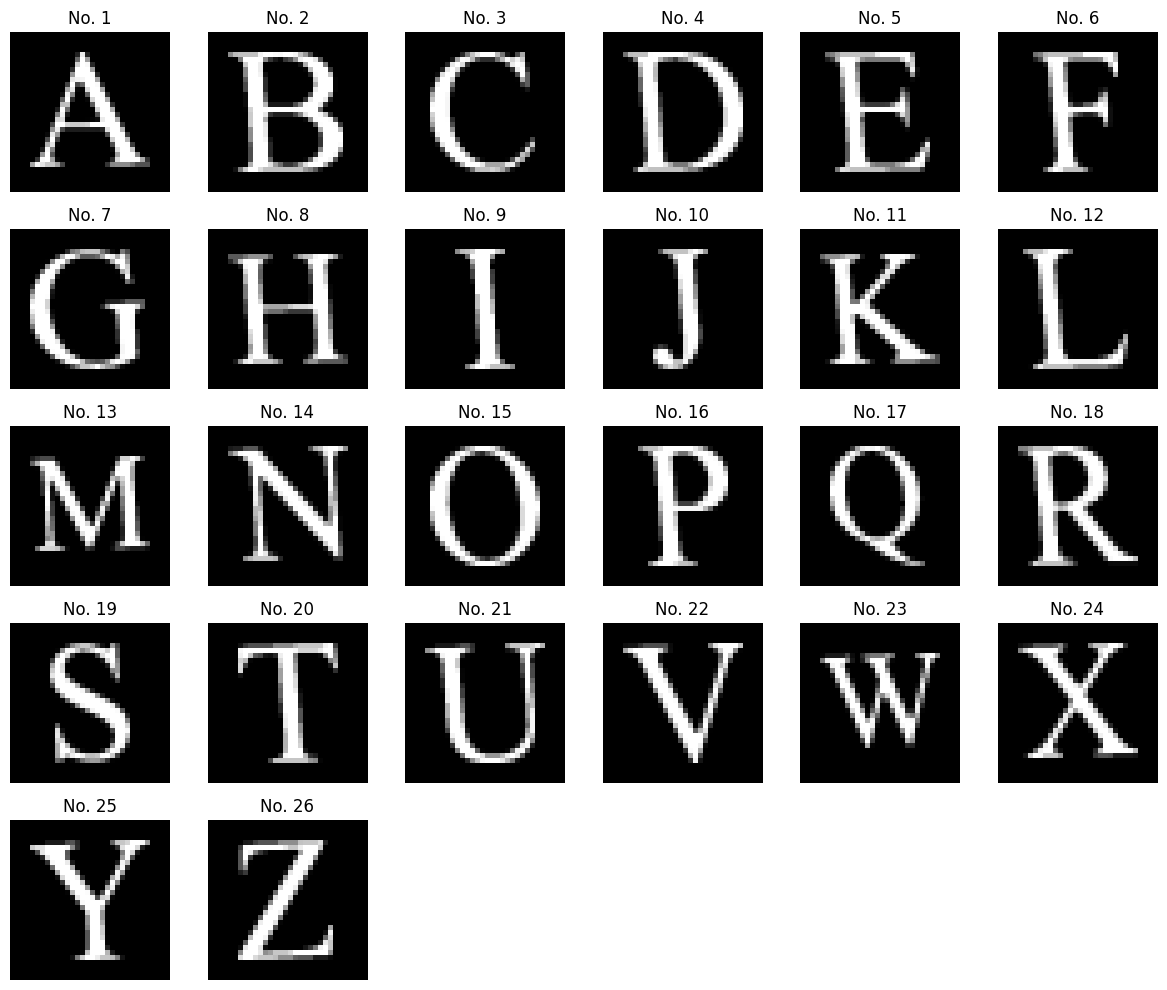

尺寸统一完成！
数据尺寸： (26, 32, 32)


In [8]:
# 把单个字母整理成32×32像素，保持比例并居中
def normalize_letter(crop):
    # 找到白色字母实际占据的位置
    ys, xs = np.where(crop > 0)

    if len(xs) == 0:
        raise ValueError("发现没有字母的空白图片，请检查分割结果。")

    # 去掉周围多余的黑色空白
    glyph = crop[
        ys.min():ys.max() + 1,
        xs.min():xs.max() + 1
    ]

    h, w = glyph.shape

    # 字母最长的一边缩放到24像素，给周围留出空白
    scale = 24 / max(h, w)
    new_width = max(1, int(round(w * scale)))
    new_height = max(1, int(round(h * scale)))

    # 等比例缩放
    resized = cv2.resize(
        glyph,
        (new_width, new_height),
        interpolation=cv2.INTER_AREA
    )

    # 建立32×32的黑色画布
    canvas = np.zeros((32, 32), dtype=np.uint8)

    # 计算居中放置的位置
    start_x = (32 - new_width) // 2
    start_y = (32 - new_height) // 2

    # 把字母放到画布中央
    canvas[
        start_y:start_y + new_height,
        start_x:start_x + new_width
    ] = resized

    return canvas


# 对26个字母逐个执行相同处理
normalized_letters = np.stack([
    normalize_letter(crop) for crop in letter_crops
])

# 展示整理后的字母
plt.figure(figsize=(12, 10))

for i, image in enumerate(normalized_letters):
    plt.subplot(5, 6, i + 1)
    plt.imshow(
        image,
        cmap="gray",
        vmin=0,
        vmax=255,
        interpolation="nearest"
    )
    plt.title(f"No. {i + 1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

print("尺寸统一完成！")
print("数据尺寸：", normalized_letters.shape)

In [9]:
# 查找Colab中可以使用的字体文件
from pathlib import Path

font_paths = sorted(
    Path("/usr/share/fonts").rglob("*.ttf")
)

print("找到的字体文件数量：", len(font_paths))
print("下面显示前30个字体文件：")

for path in font_paths[:30]:
    print(path.name)

找到的字体文件数量： 13
下面显示前30个字体文件：
Humor-Sans.ttf
LiberationMono-Bold.ttf
LiberationMono-BoldItalic.ttf
LiberationMono-Italic.ttf
LiberationMono-Regular.ttf
LiberationSans-Bold.ttf
LiberationSans-BoldItalic.ttf
LiberationSans-Italic.ttf
LiberationSans-Regular.ttf
LiberationSerif-Bold.ttf
LiberationSerif-BoldItalic.ttf
LiberationSerif-Italic.ttf
LiberationSerif-Regular.ttf


训练图片生成完成！
图片数据尺寸： (2600, 32, 32)
答案数量： 2600


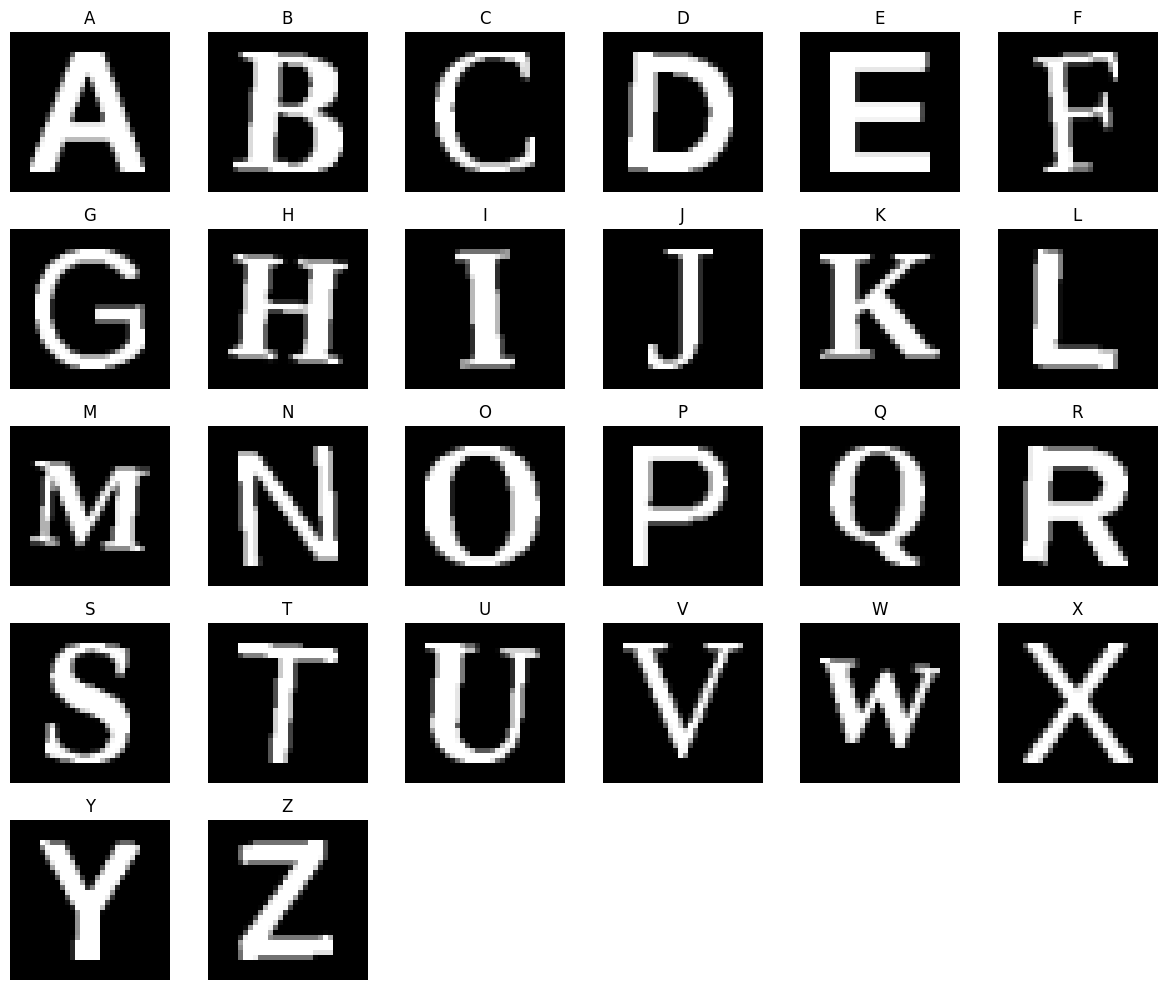

In [10]:
from PIL import Image, ImageDraw, ImageFont, ImageFilter

# 选择4种字体
wanted_fonts = {
    "LiberationSerif-Regular.ttf",
    "LiberationSerif-Bold.ttf",
    "LiberationSans-Regular.ttf",
    "LiberationSans-Bold.ttf"
}

training_fonts = [
    path for path in font_paths
    if path.name in wanted_fonts
]

if len(training_fonts) != 4:
    raise ValueError("没有找到预期的4种字体，请把输出发给我。")

# 固定随机种子，便于重复实验
rng = np.random.default_rng(42)

alphabet = "ABCDEFGHIJKLMNOPQRSTUVWXYZ"
samples_per_letter = 100

# 定义生成单张字符图片的方法
def generate_letter(character):
    # 随机选择一种字体和字号
    font_path = training_fonts[
        int(rng.integers(len(training_fonts)))
    ]
    font_size = int(rng.integers(48, 73))
    font = ImageFont.truetype(str(font_path), font_size)

    # 建立黑色画布
    canvas = Image.new("L", (96, 96), 0)
    draw = ImageDraw.Draw(canvas)

    # 计算字母的位置，让它位于中央
    box = draw.textbbox((0, 0), character, font=font)
    x = (96 - (box[2] - box[0])) / 2 - box[0]
    y = (96 - (box[3] - box[1])) / 2 - box[1]

    # 写出白色字母
    draw.text((x, y), character, font=font, fill=255)

    # 加入少量旋转和模糊变化
    canvas = canvas.rotate(
        float(rng.uniform(-6, 6)),
        resample=Image.Resampling.BICUBIC,
        fillcolor=0
    )

    canvas = canvas.filter(
        ImageFilter.GaussianBlur(
            radius=float(rng.uniform(0, 0.6))
        )
    )

    # 转为二值图，再使用前面相同的尺寸整理方法
    image = np.array(canvas)

    _, binary = cv2.threshold(
        image, 0, 255,
        cv2.THRESH_BINARY | cv2.THRESH_OTSU
    )

    return normalize_letter(binary)


# 生成图片，同时记录每张图的正确答案
synthetic_images = []
synthetic_labels = []

for character in alphabet:
    for _ in range(samples_per_letter):
        synthetic_images.append(generate_letter(character))
        synthetic_labels.append(character)

synthetic_images = np.stack(synthetic_images)
synthetic_labels = np.array(synthetic_labels)

print("训练图片生成完成！")
print("图片数据尺寸：", synthetic_images.shape)
print("答案数量：", len(synthetic_labels))

# 每种字母展示一张生成的图片
plt.figure(figsize=(12, 10))

for i, character in enumerate(alphabet):
    plt.subplot(5, 6, i + 1)
    plt.imshow(
        synthetic_images[i * samples_per_letter],
        cmap="gray",
        vmin=0,
        vmax=255
    )
    plt.title(character)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [11]:
# 准备SVM训练工具
%pip -q install scikit-learn

from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# 定义适用于32×32字母图片的HOG方法
def hog32(image):
    # 计算水平和垂直方向的亮暗变化
    gx = cv2.Sobel(image, cv2.CV_32F, 1, 0)
    gy = cv2.Sobel(image, cv2.CV_32F, 0, 1)

    magnitude, angle = cv2.cartToPolar(gx, gy)

    # 把方向分为16类
    bins = (angle * 16 / (2 * np.pi)).astype(np.int32) % 16

    features = []

    # 将32×32图片分成4块，每块16×16
    for y in (0, 16):
        for x in (0, 16):
            block_bins = bins[y:y + 16, x:x + 16]
            block_magnitude = magnitude[y:y + 16, x:x + 16]

            histogram = np.bincount(
                block_bins.ravel(),
                weights=block_magnitude.ravel(),
                minlength=16
            )

            features.extend(histogram)

    return np.array(features, dtype=np.float32)


# 从2600张生成图片中提取HOG特征
letter_train_features = np.array([
    hog32(image) for image in synthetic_images
], dtype=np.float32)

print("HOG特征提取完成！")
print("训练特征尺寸：", letter_train_features.shape)

# 创建“标准化＋线性SVM”模型
letter_svm = make_pipeline(
    StandardScaler(),
    SVC(kernel="linear", C=2.67)
)

print("正在训练字母SVM，请稍等……")

# 只使用电脑生成的图片及其正确答案进行训练
letter_svm.fit(letter_train_features, synthetic_labels)

print("字母SVM训练完成！")
print("训练图片数量：", len(letter_train_features))
print("模型学到的类别数量：", len(letter_svm.classes_))
print("类别：", " ".join(letter_svm.classes_))

HOG特征提取完成！
训练特征尺寸： (2600, 64)
正在训练字母SVM，请稍等……
字母SVM训练完成！
训练图片数量： 2600
模型学到的类别数量： 26
类别： A B C D E F G H I J K L M N O P Q R S T U V W X Y Z


真实文字： ABCDEFGHIJKLMNOPQRSTUVWXYZ
识别文字： ABCDEFGHIJKLMNOPQRSTUVWXYZ
字符总数： 26
识别正确： 26
识别错误： 0
本张照片的字符准确率：100.00%


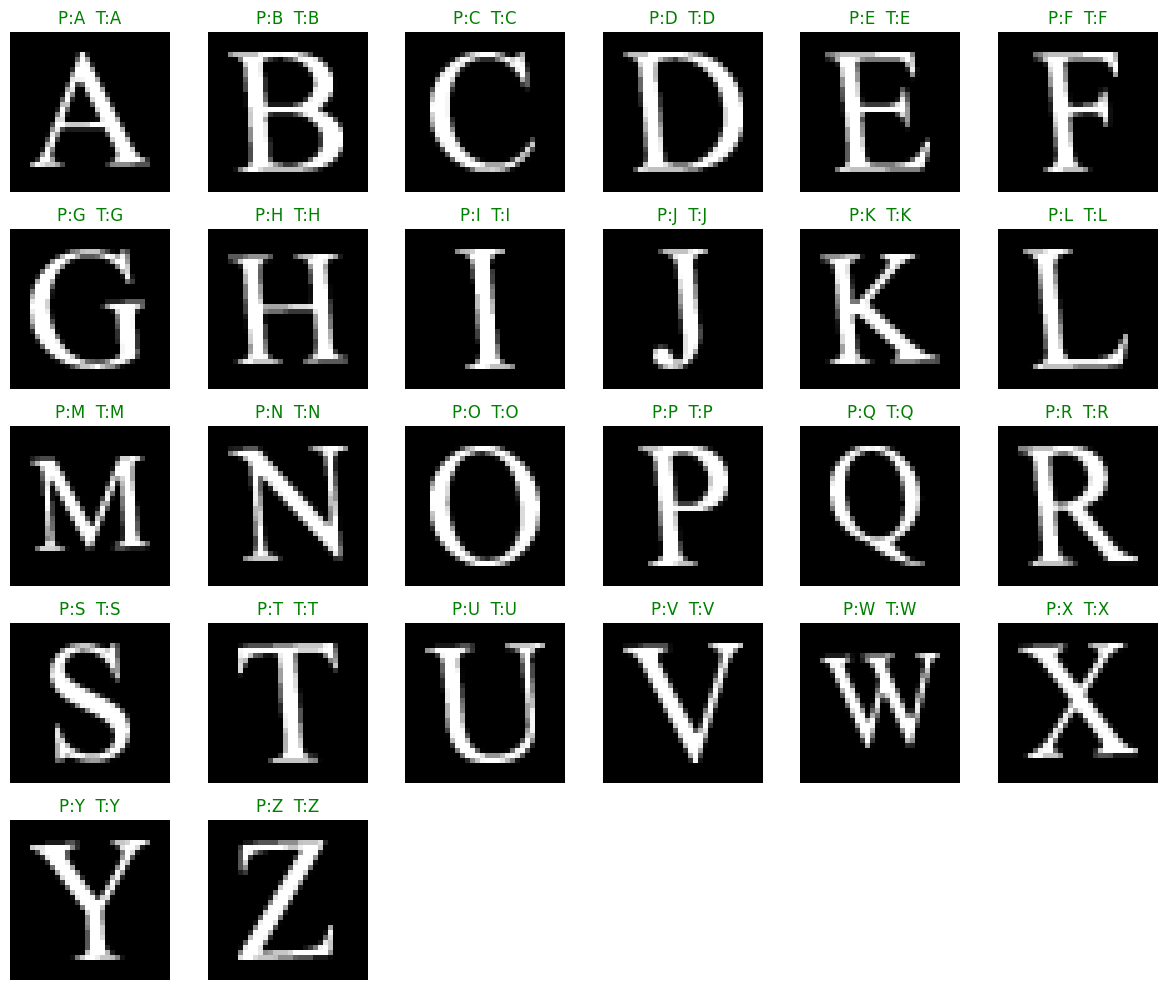

In [12]:
# 提取实拍字母的HOG特征
photo_features = np.array([
    hog32(image) for image in normalized_letters
], dtype=np.float32)

# 让模型预测，只提供图片特征
photo_predictions = letter_svm.predict(photo_features)

# 预测完成后，提供这张照片的真实文字用于评分
# 我们已经检查过：这张照片按阅读顺序是A到Z
photo_truth = np.array(list("ABCDEFGHIJKLMNOPQRSTUVWXYZ"))

if len(photo_predictions) != len(photo_truth):
    raise ValueError("字符数量与真实文字不一致，请先检查分割结果。")

# 计算识别正确的数量和准确率
photo_correct = int(np.sum(photo_predictions == photo_truth))
photo_total = len(photo_truth)
photo_accuracy = photo_correct / photo_total * 100

print("真实文字：", "".join(photo_truth))
print("识别文字：", "".join(photo_predictions))
print("字符总数：", photo_total)
print("识别正确：", photo_correct)
print("识别错误：", photo_total - photo_correct)
print(f"本张照片的字符准确率：{photo_accuracy:.2f}%")

# 显示每个字母及其预测结果
plt.figure(figsize=(12, 10))

for i, image in enumerate(normalized_letters):
    predicted = photo_predictions[i]
    actual = photo_truth[i]

    # 正确用绿色标题，错误用红色标题
    title_color = "green" if predicted == actual else "red"

    plt.subplot(5, 6, i + 1)
    plt.imshow(image, cmap="gray", vmin=0, vmax=255)
    plt.title(
        f"P:{predicted}  T:{actual}",
        color=title_color
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

Saving luan.jpg to luan.jpg


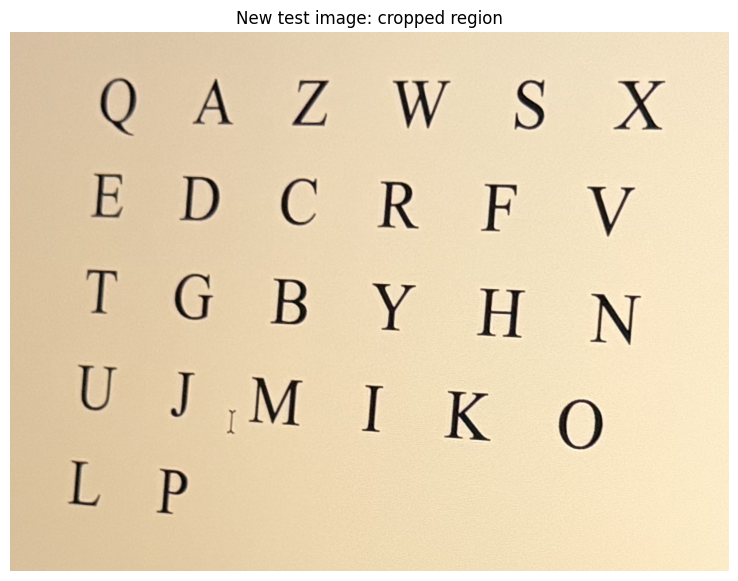

新照片读取完成： luan.jpg
裁剪尺寸： (1028, 1371)


In [13]:
from google.colab import files
from PIL import Image, ImageOps
import io

# 上传一张新的测试照片
new_test_upload = files.upload()

if len(new_test_upload) != 1:
    raise ValueError("这一步请只选择一张新的测试照片。")

# 读取照片，并处理手机记录的方向
new_test_name = next(iter(new_test_upload))
photo = Image.open(
    io.BytesIO(new_test_upload[new_test_name])
)
photo = ImageOps.exif_transpose(photo)
new_test_photo = np.array(photo.convert("RGB"))

# 根据这张照片中字母的位置，设置初始裁剪范围
height, width = new_test_photo.shape[:2]

new_test_roi = new_test_photo[
    int(height * 0.33):int(height * 0.57),
    int(width * 0.36):int(width * 0.60)
].copy()

# 显示裁剪结果
plt.figure(figsize=(10, 7))
plt.imshow(new_test_roi)
plt.title("New test image: cropped region")
plt.axis("off")
plt.show()

print("新照片读取完成：", new_test_name)
print("裁剪尺寸：", new_test_roi.shape[:2])

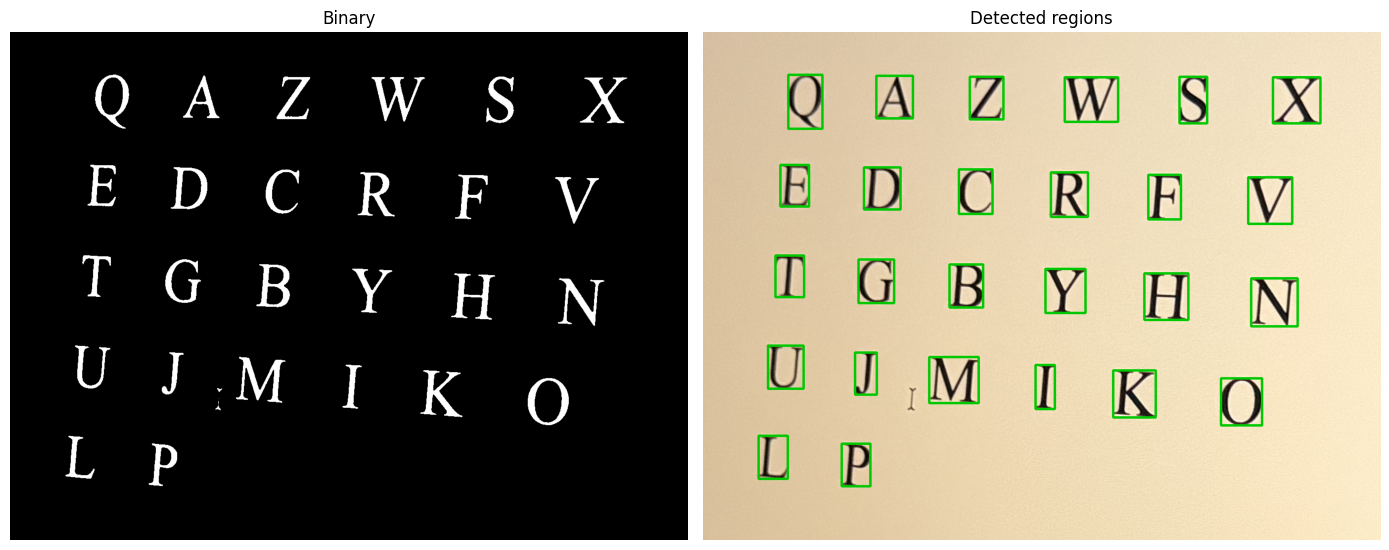

自动选择的阈值： 139.0
检测到的候选字符数量： 26


In [14]:
# 使用与前一张照片相同的预处理方法
new_test_gray = cv2.cvtColor(
    new_test_roi, cv2.COLOR_RGB2GRAY
)

new_test_blurred = cv2.GaussianBlur(
    new_test_gray, (5, 5), 0
)

new_threshold, new_test_binary = cv2.threshold(
    new_test_blurred,
    0,
    255,
    cv2.THRESH_BINARY_INV | cv2.THRESH_OTSU
)

# 寻找字符外轮廓
new_contours, _ = cv2.findContours(
    new_test_binary.copy(),
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

# 使用前一张照片相同的尺寸过滤规则
new_roi_height, new_roi_width = new_test_binary.shape
new_test_boxes = []

for contour in new_contours:
    x, y, w, h = cv2.boundingRect(contour)
    area = cv2.contourArea(contour)

    if (
        h >= new_roi_height * 0.04
        and h <= new_roi_height * 0.25
        and w >= 3
        and area >= new_roi_height * new_roi_width * 0.00005
    ):
        new_test_boxes.append((x, y, w, h))

# 画出检测结果
new_test_boxed = new_test_roi.copy()

for x, y, w, h in new_test_boxes:
    cv2.rectangle(
        new_test_boxed,
        (x, y),
        (x + w, y + h),
        (0, 200, 0),
        3
    )

# 对比二值图和框选结果
plt.figure(figsize=(14, 7))

plt.subplot(1, 2, 1)
plt.imshow(new_test_binary, cmap="gray")
plt.title("Binary")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(new_test_boxed)
plt.title("Detected regions")
plt.axis("off")

plt.tight_layout()
plt.show()

print("自动选择的阈值：", new_threshold)
print("检测到的候选字符数量：", len(new_test_boxes))

每行字符数量： [6, 6, 6, 6, 2]
真实文字： QAZWSXEDCRFVTGBYHNUJMIKOLP
识别文字： QAZWSXEDCRFVTGBYHNUJMIKOLP
字符总数： 26
识别正确： 26
识别错误： 0
本张照片的字符准确率：100.00%


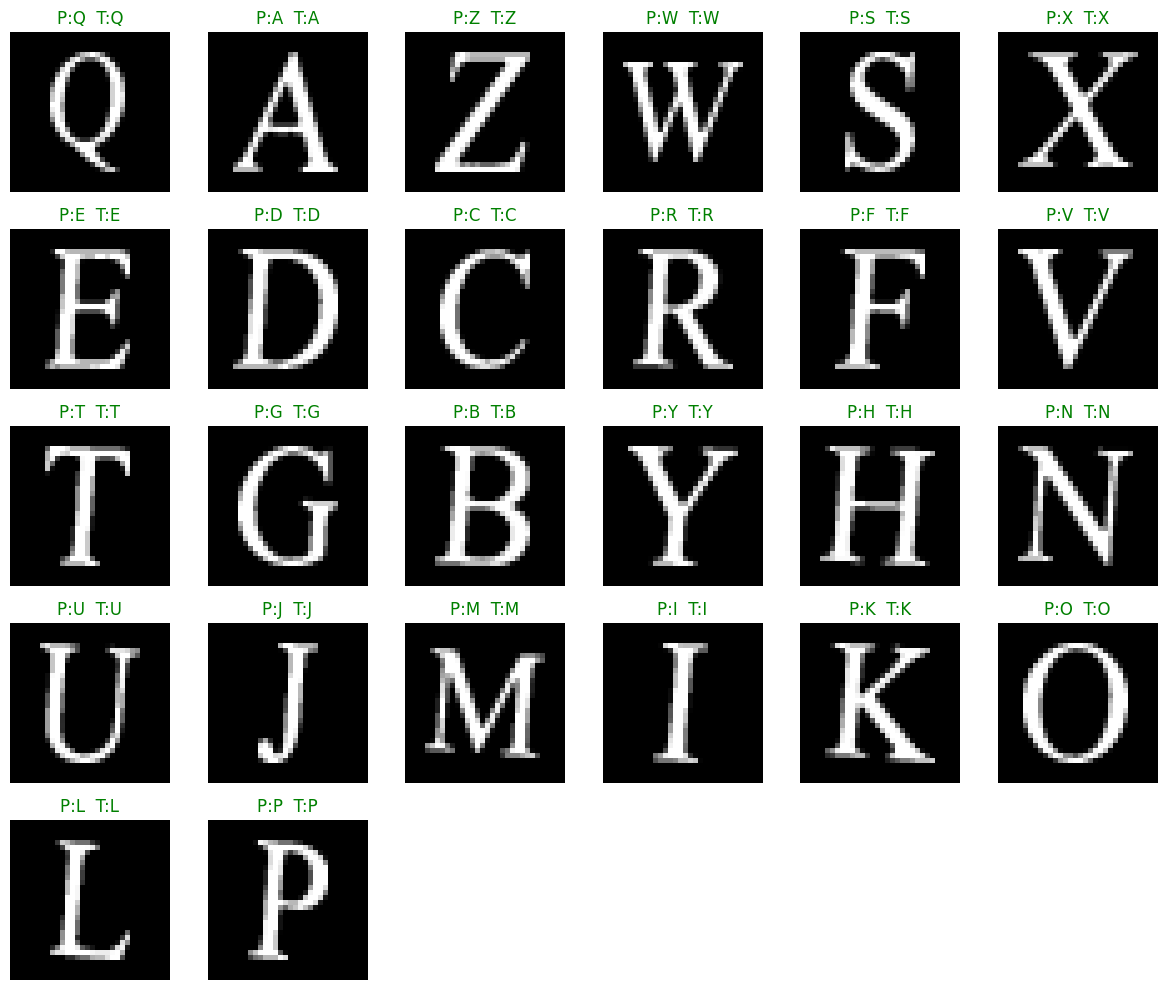

In [15]:
# 一、按位置分行，再按每行从左到右排序
row_tolerance = np.median([b[3] for b in new_test_boxes]) * 0.65

boxes_by_height = sorted(
    new_test_boxes,
    key=lambda b: b[1] + b[3] / 2
)

new_rows = []

for box in boxes_by_height:
    center_y = box[1] + box[3] / 2

    if (
        not new_rows
        or center_y - np.mean([
            b[1] + b[3] / 2 for b in new_rows[-1]
        ]) > row_tolerance
    ):
        new_rows.append([])

    new_rows[-1].append(box)

new_ordered_boxes = []

for row in new_rows:
    row.sort(key=lambda b: b[0])
    new_ordered_boxes.extend(row)

print("每行字符数量：", [len(row) for row in new_rows])

# 二、逐个裁出字符，并用原来的方法整理成32×32
new_normalized_letters = []

for x, y, w, h in new_ordered_boxes:
    padding = max(2, int(h * 0.05))

    x_start = max(0, x - padding)
    y_start = max(0, y - padding)
    x_end = min(new_test_binary.shape[1], x + w + padding)
    y_end = min(new_test_binary.shape[0], y + h + padding)

    crop = new_test_binary[
        y_start:y_end, x_start:x_end
    ].copy()

    new_normalized_letters.append(normalize_letter(crop))

new_normalized_letters = np.stack(new_normalized_letters)

# 三、提取HOG特征，用已经训练好的模型预测
new_features = np.array([
    hog32(image) for image in new_normalized_letters
], dtype=np.float32)

new_predictions = letter_svm.predict(new_features)

# 四、预测完成后，用实际文字评分
new_truth = np.array(list("QAZWSXEDCRFVTGBYHNUJMIKOLP"))

if [len(row) for row in new_rows] != [6, 6, 6, 6, 2]:
    raise ValueError("分行结果与照片排版不一致，请先检查排序。")

if len(new_predictions) != len(new_truth):
    raise ValueError("字符数量不一致，请先检查分割。")

new_correct = int(np.sum(new_predictions == new_truth))
new_total = len(new_truth)
new_accuracy = new_correct / new_total * 100

print("真实文字：", "".join(new_truth))
print("识别文字：", "".join(new_predictions))
print("字符总数：", new_total)
print("识别正确：", new_correct)
print("识别错误：", new_total - new_correct)
print(f"本张照片的字符准确率：{new_accuracy:.2f}%")

# 五、展示每个字符的实际预测结果
plt.figure(figsize=(12, 10))

for i, image in enumerate(new_normalized_letters):
    predicted = new_predictions[i]
    actual = new_truth[i]
    title_color = "green" if predicted == actual else "red"

    plt.subplot(5, 6, i + 1)
    plt.imshow(image, cmap="gray", vmin=0, vmax=255)
    plt.title(
        f"P:{predicted}  T:{actual}",
        color=title_color
    )
    plt.axis("off")

plt.tight_layout()
plt.show()